## Soal 1

### 1.1 Load and preview the data

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.cluster import KMeans
from sklearn.metrics import accuracy_score
from sklearn.preprocessing import StandardScaler

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (8, 5)

# 1. Load and preview the data
df = pd.read_pickle("users_data_cleaned.pickle")
display(df.head())


,user_id,number_transactions,total_amount_usd,age,job,marital,education,default,housing,loan,contact,duration,campaign,pdays,previous,poutcome,term_deposit,date_joined,device
0,9231c446-cb16-4b2b-a7f7-ddfc8b25aaf6,3.0,2143.0,58,management,married,tertiary,False,True,False,None,261,1,-1,0,None,False,1998-08-23,mobile
1,bb92765a-08de-4963-b432-496524b39157,NaN,NaN,44,technician,single,secondary,False,True,False,None,151,1,-1,0,None,False,2008-07-15,desktop
2,573de577-49ef-42b9-83da-d3cfb817b5c1,2.0,2.0,33,entrepreneur,married,secondary,False,True,True,None,76,1,-1,0,None,False,2002-06-04,mobile
3,d6b66b9d-7c8f-4257-a682-e136f640b7e3,NaN,NaN,47,blue-collar,married,None,False,True,False,None,92,1,-1,0,None,False,1995-06-29,tablet
4,fade0b20-7594-4d9a-84cd-c02f79b1b526,1.0,1.0,33,None,single,None,False,False,False,None,198,1,-1,0,None,False,1995-08-01,mobile


### 1.2 Check the shape of the data

In [ ]:
print("Shape:", df.shape)
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])


Shape: (45209, 19)
Rows: 45209
Columns: 19


### 1.3 Check the data types

In [ ]:
print(df.dtypes)


user_id                        object
number_transactions           float64
total_amount_usd              float64
age                             int64
job                            object
marital                        object
education                      object
default                          bool
housing                          bool
loan                             bool
contact                        object
duration                        int64
campaign                        int64
pdays                           int64
previous                        int64
poutcome                       object
term_deposit                     bool
date_joined            datetime64[ns]
device                         object
dtype: object


### 1.4 Check for correlations

In [ ]:
numeric_df = df.select_dtypes(include="number")
display(numeric_df.corr())


,number_transactions,total_amount_usd,age,duration,campaign,pdays,previous
number_transactions,1.000000,-0.163409,-0.008813,-0.017220,0.026431,-0.030751,-0.023046
total_amount_usd,-0.163409,1.000000,0.095839,0.022586,-0.017274,0.006435,0.016952
age,-0.008813,0.095839,1.000000,-0.004645,0.004767,-0.023745,0.001297
duration,-0.017220,0.022586,-0.004645,1.000000,-0.084551,-0.001549,0.001213
campaign,0.026431,-0.017274,0.004767,-0.084551,1.000000,-0.088636,-0.032860
pdays,-0.030751,0.006435,-0.023745,-0.001549,-0.088636,1.000000,0.454817
previous,-0.023046,0.016952,0.001297,0.001213,-0.032860,0.454817,1.000000


### 1.5 Generate summary statistics for numerical data only

In [ ]:
display(df.describe(include="number"))


,number_transactions,total_amount_usd,age,duration,campaign,pdays,previous
count,35210.000000,35210.000000,45209.000000,45209.000000,45209.000000,45209.000000,45209.000000
mean,3.977052,1369.417751,40.935853,258.153067,2.763897,40.199651,0.580349
std,3.814329,3063.412688,10.618653,257.525446,3.098076,100.130586,2.303489
min,1.000000,-8019.000000,18.000000,0.000000,1.000000,-1.000000,0.000000
25%,2.000000,73.000000,33.000000,103.000000,1.000000,-1.000000,0.000000
50%,3.000000,451.000000,39.000000,180.000000,2.000000,-1.000000,0.000000
75%,4.000000,1438.000000,48.000000,319.000000,3.000000,-1.000000,0.000000
max,20.000000,102127.000000,95.000000,4918.000000,63.000000,871.000000,275.000000


### 1.6 Plot Histograms for all numerical columns

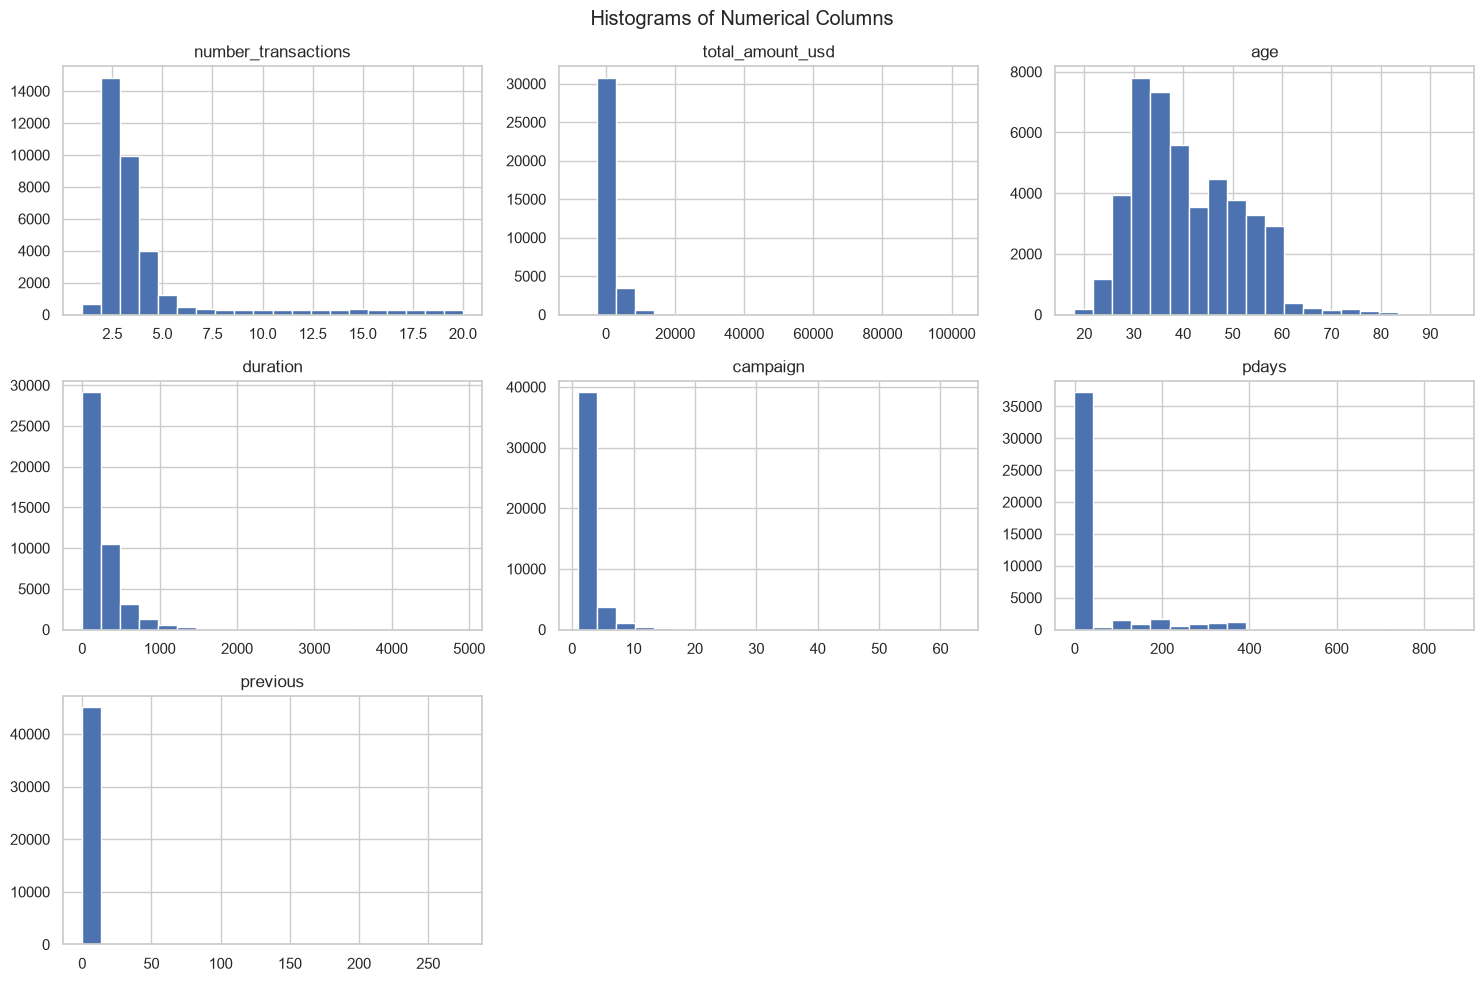

In [ ]:
numeric_df.hist(figsize=(15, 10), bins=20)
plt.suptitle("Histograms of Numerical Columns")
plt.tight_layout()
plt.show()


### 1.7 Generate a box plot for age, dan number_transactions

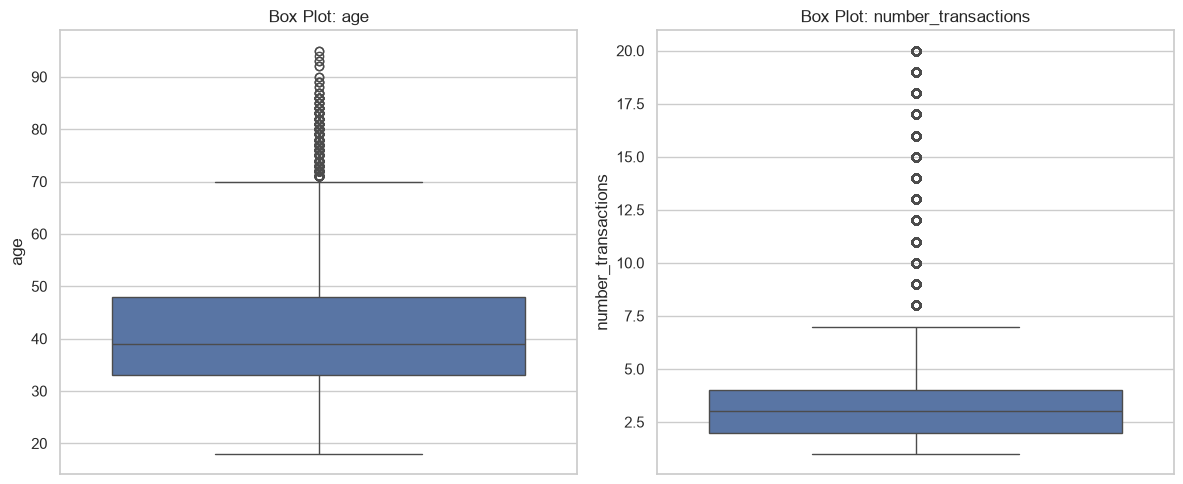

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
sns.boxplot(data=df, y="age", ax=axes[0])
axes[0].set_title("Box Plot: age")
sns.boxplot(data=df, y="number_transactions", ax=axes[1])
axes[1].set_title("Box Plot: number_transactions")
plt.tight_layout()
plt.show()


### 1.8 Generate a lineplot for date_joined to total_amount_usd

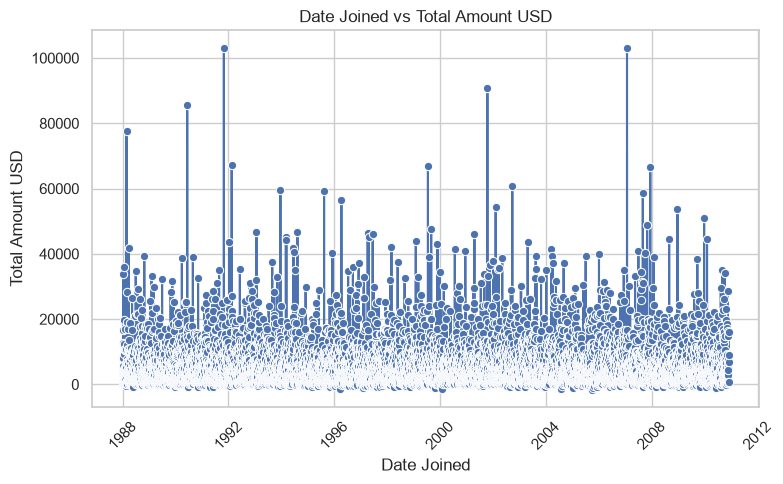

In [ ]:
df["date_joined"] = pd.to_datetime(df["date_joined"])
line_data = (
    df.groupby("date_joined", as_index=False)["total_amount_usd"]
      .sum()
      .sort_values("date_joined")
)
sns.lineplot(data=line_data, x="date_joined", y="total_amount_usd", marker="o")
plt.title("Date Joined vs Total Amount USD")
plt.xlabel("Date Joined")
plt.ylabel("Total Amount USD")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


### 1.9 Generate scatter plots comparing total_amount_usd to number_transaction

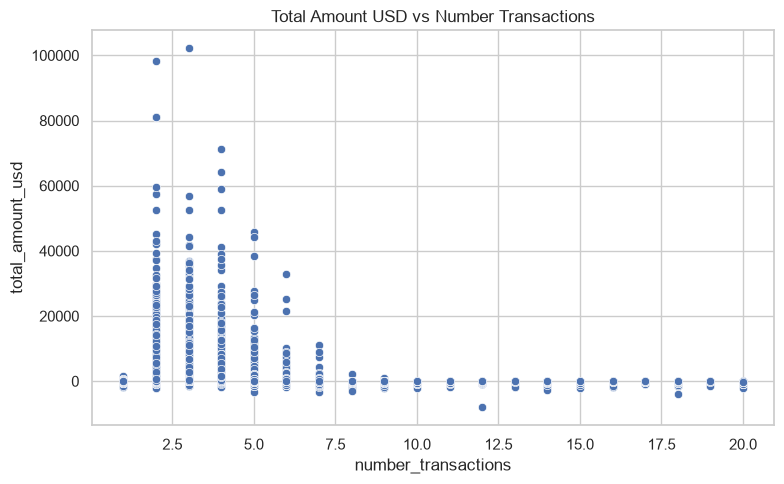

In [ ]:
sns.scatterplot(data=df, x="number_transactions", y="total_amount_usd")
plt.title("Total Amount USD vs Number Transactions")
plt.tight_layout()
plt.show()


### 1.10 Generate Horizontal bar charts for job

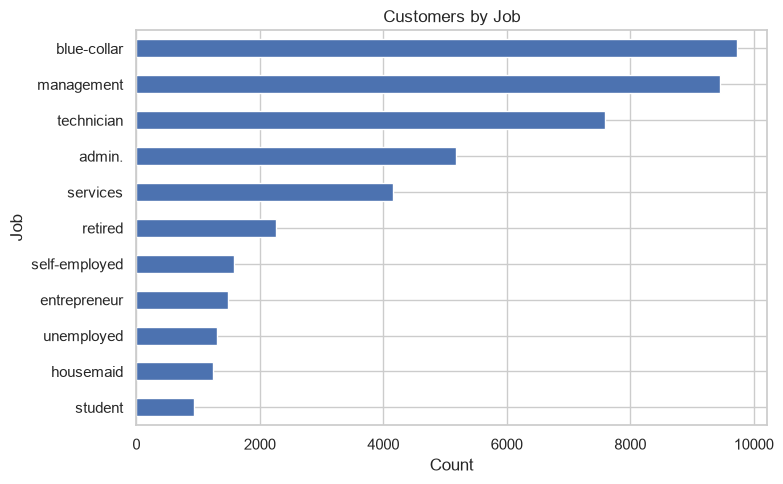

In [ ]:
df["job"].value_counts().sort_values().plot(kind="barh")
plt.title("Customers by Job")
plt.xlabel("Count")
plt.ylabel("Job")
plt.tight_layout()
plt.show()


### 1.11 Generate Horizontal bar charts for marital

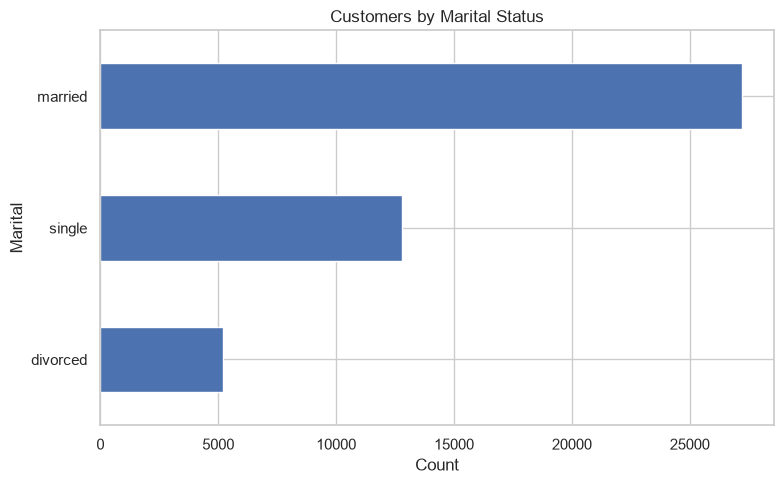

In [ ]:
df["marital"].value_counts().sort_values().plot(kind="barh")
plt.title("Customers by Marital Status")
plt.xlabel("Count")
plt.ylabel("Marital")
plt.tight_layout()
plt.show()


### 1.12 Generate a heatmap for future correlations

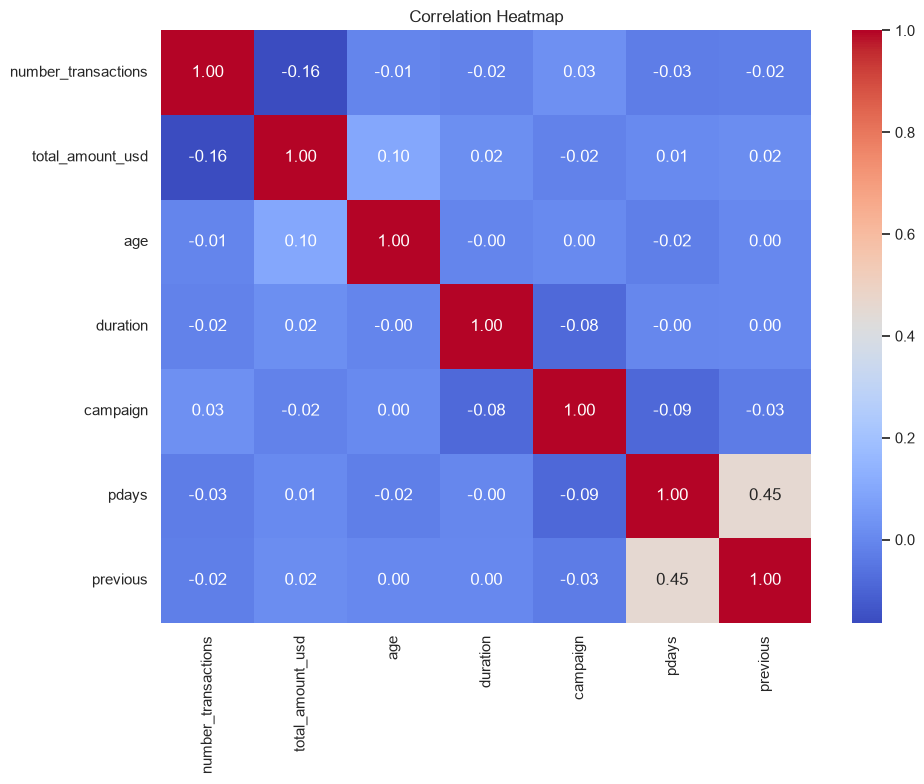

In [ ]:
plt.figure(figsize=(10, 8))
sns.heatmap(numeric_df.corr(), annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()


### 1.13 Identify Missing Values

In [ ]:
print("Missing values per column:")
print(df.isnull().sum())
print("\nTotal missing values:", df.isnull().sum().sum())


Missing values per column:
user_id                    0
number_transactions     9999
total_amount_usd        9999
age                        0
job                      288
marital                    0
education               1857
default                    0
housing                    0
loan                       0
contact                13018
duration                   0
campaign                   0
pdays                      0
previous                   0
poutcome               36957
term_deposit               0
date_joined               30
device                    94
dtype: int64

Total missing values: 72242


## Soal 2

### 2.1.a Membaca file real_estate.csv 

In [ ]:
df_estate = pd.read_csv("real_estate.csv")
display(df_estate.head())

,No,X1 transaction date,X2 house age,X3 distance to the nearest MRT station,X4 number of convenience stores,X5 latitude,X6 longitude,Y house price of unit area
0,1,2012.917,32.0,84.87882,10,24.98298,121.54024,37.9
1,2,2012.917,19.5,306.59470,9,24.98034,121.53951,42.2
2,3,2013.583,13.3,561.98450,5,24.98746,121.54391,47.3
3,4,2013.500,13.3,561.98450,5,24.98746,121.54391,54.8
4,5,2012.833,5.0,390.56840,5,24.97937,121.54245,43.1


### 2.1.b Menampilkan variable dalam dataset

In [ ]:
TRANSCATION_DATE = "X1 transaction date"
HOUSE_PRICE = "Y house price of unit area"

X = df_estate[[TRANSCATION_DATE]]
y = df_estate[HOUSE_PRICE]

display(X.head())
display(y.head())


,X1 transaction date
0,2012.917
1,2012.917
2,2013.583
3,2013.500
4,2012.833


0    37.9
1    42.2
2    47.3
3    54.8
4    43.1
Name: Y house price of unit area, dtype: float64

### 2.1.c Menampilkan data yang di-split (train: 80 % & test:20%)

In [113]:
X = df_estate[['X1 transaction date']]
y = df_estate['Y house price of unit area']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)  
print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)

X_train shape: (331, 1)
X_test shape: (83, 1)


### 2.1.d Memanggil LinearRegression()

In [114]:
model = LinearRegression()
model.fit(X_train, y_train)


,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](1,)",[3.65]
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](1,)",['X1 transaction date']
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,-7306
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,1
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(1)


### 2.1.e Menampilkan hasil predict dari data test

In [115]:
y_pred = model.predict(X_test)
print(y_pred)

[38.39269804 37.78346476 38.08625735 37.48067217 36.56864631 39.91030908
 37.48067217 38.69549063 37.48067217 39.91030908 39.60751649 39.60751649
 37.17423148 37.17423148 38.08625735 39.3047239  39.3047239  37.17423148
 37.48067217 38.08625735 37.78346476 39.3047239  38.69549063 39.60751649
 36.87143889 37.17423148 37.17423148 37.17423148 37.48067217 38.08625735
 39.60751649 38.99828321 36.56864631 37.78346476 38.69549063 38.08625735
 37.48067217 37.78346476 39.91030908 38.08625735 39.91030908 38.39269804
 37.48067217 36.87143889 36.87143889 37.48067217 37.48067217 36.87143889
 36.56864631 36.56864631 38.69549063 38.69549063 39.3047239  38.39269804
 38.08625735 38.39269804 39.3047239  37.48067217 37.17423148 38.39269804
 38.08625735 38.08625735 38.39269804 36.56864631 39.91030908 38.69549063
 37.48067217 39.3047239  37.48067217 38.99828321 38.08625735 39.91030908
 37.48067217 38.08625735 37.78346476 36.87143889 38.08625735 36.56864631
 36.87143889 39.3047239  38.69549063 36.56864631 36

### Hitung lah Intercept, Slope, R-Square

In [116]:
print("Intercept:", model.intercept_)
print("Slope:", model.coef_[0])
print("R-Square (test):", model.score(X_test, y_test))


Intercept: -7305.848808943734
Slope: 3.6481034643338566
R-Square (test): -0.007387015426280286


### 2.1.f dan 2.1.g

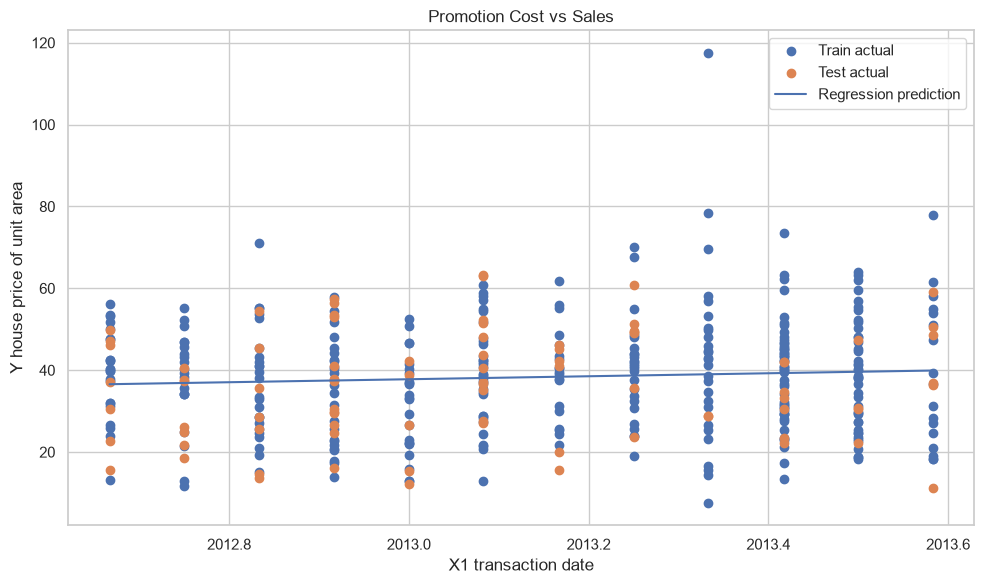

In [ ]:
plt.figure(figsize=(10, 6))
plt.scatter(X_train[TRANSCATION_DATE], y_train, label="Train actual")
plt.scatter(X_test[TRANSCATION_DATE], y_test, label="Test actual")

x_min = df_estate[TRANSCATION_DATE].min()
x_max = df_estate[TRANSCATION_DATE].max()
x_line = np.linspace(x_min, x_max, 200).reshape(-1, 1)
x_line_df = pd.DataFrame(x_line, columns=[TRANSCATION_DATE])
plt.plot(x_line, model.predict(x_line_df), label="Regression prediction")

plt.title("Promotion Cost vs Sales")
plt.xlabel(TRANSCATION_DATE)
plt.ylabel(HOUSE_PRICE)
plt.legend()
plt.tight_layout()
plt.show()


## Soal 3

In [123]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans

data = pd.read_csv("konsumen.csv", delimiter=";")

In [ ]:
print("7 Data Teratas:")
print(data.head(7))

7 Data Teratas:
   No  Gaji  Pengeluaran
0   1  2500         1750
1   2  3800         4200
2   3  3900         3800
3   4  4350         5500
4   5  4400         3200
5   6  5500         5450
6   7  5600         5950


In [125]:
# Menghapus kolom No
if 'No' in data.columns:
    data = data.drop(columns=['No'])

In [126]:
print("9 Data Teratas:")
print(data.head(9))

9 Data Teratas:
   Gaji  Pengeluaran
0  2500         1750
1  3800         4200
2  3900         3800
3  4350         5500
4  4400         3200
5  5500         5450
6  5600         5950
7  5750         4100
8  6850         6050


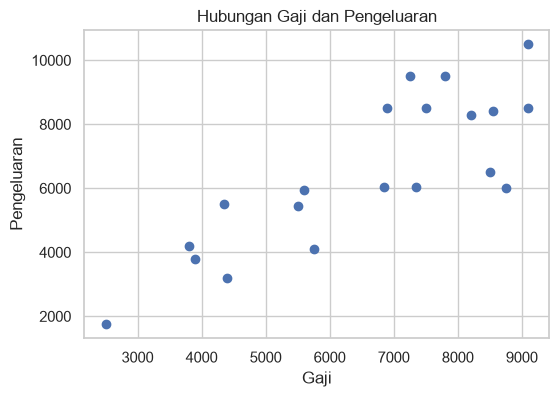

In [127]:
plt.figure(figsize=(6, 4))
plt.scatter(data['Gaji'], data['Pengeluaran'])
plt.title("Hubungan Gaji dan Pengeluaran")
plt.xlabel("Gaji")
plt.ylabel("Pengeluaran")
plt.show()

In [128]:
kmeans = KMeans(n_clusters=2, random_state=42)
data['Klaster'] = kmeans.fit_predict(data[['Gaji', 'Pengeluaran']])

c:\Users\WIN11\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(


In [ ]:
print("\nPusat Klaster:")
print(kmeans.cluster_centers_)


Pusat Klaster:
[[4475.   4243.75]
 [7987.5  8025.  ]]


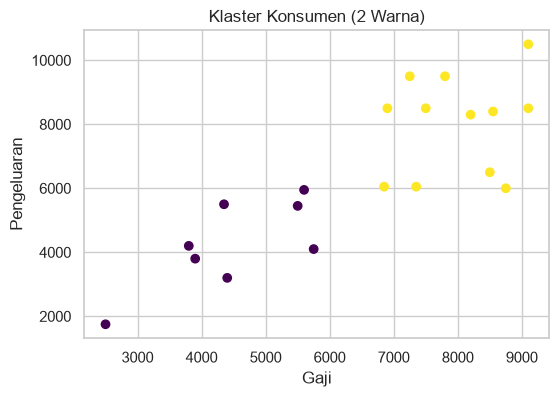

In [130]:
# Menampilkan Grafik Konsumen yang memiliki 2 warna berbeda
plt.figure(figsize=(6, 4))
plt.scatter(data['Gaji'], data['Pengeluaran'], c=data['Klaster'], cmap='viridis')
plt.title("Klaster Konsumen (2 Warna)")
plt.xlabel("Gaji")
plt.ylabel("Pengeluaran")
plt.show()

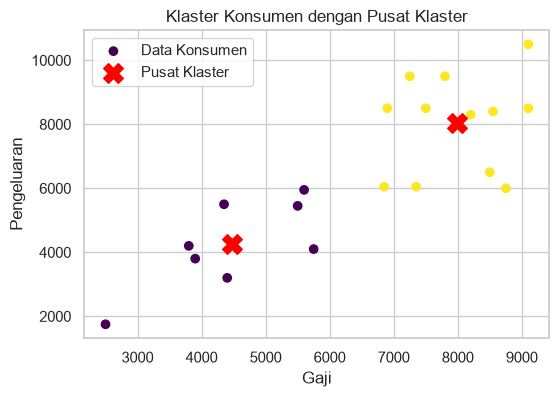

In [131]:
plt.figure(figsize=(6, 4))
plt.scatter(data['Gaji'], data['Pengeluaran'], c=data['Klaster'], cmap='viridis', label='Data Konsumen')
plt.scatter(kmeans.cluster_centers_[:, 0], kmeans.cluster_centers_[:, 1], c='red', marker='X', s=200, label='Pusat Klaster')
plt.title("Klaster Konsumen dengan Pusat Klaster")
plt.xlabel("Gaji")
plt.ylabel("Pengeluaran")
plt.legend()
plt.show()